# Exercício 5.7 — ACM dos cogumelos (UCI Mushroom)

**Objetivo:** descrever, via Análise de Correspondência Múltipla (ACM), como os atributos morfológicos se associam, usando a classe **comestível/venenoso como variável suplementar**, e verificar se algum atributo sozinho praticamente separa os dois grupos.

**Decisões metodológicas (justificadas ao longo do notebook):**

| Decisão | Escolha | Por quê |
|---|---|---|
| Classe | variável **suplementar** (fora do cálculo dos eixos) | os eixos descrevem a estrutura dos atributos; a classe é projetada depois, sem influenciar |
| `veil-type` | removida | tem um único nível (constante): não tem variância nem informação |
| `stalk-root` (ausentes) | `?` vira nível próprio **"ausente"** | ~30% dos dados; a ausência não é aleatória (checamos contra a classe); descartar linhas perderia 30% da amostra |
| Níveis raros | agrupados em `outros` se freq. < 1% (≥ 2 níveis raros na variável) | nível raro tem inércia (1−p)/Q alta e puxa eixos sozinho; mostramos análise de sensibilidade |
| Percentual de inércia | taxas brutas **e** corrigidas (Benzécri/Greenacre) | as brutas subestimam muito a qualidade do ajuste na ACM |

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.model_selection import KFold

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

## 1. Carga dos dados

`sklearn.datasets` **não** traz o Mushroom embutido (só `fetch_openml("mushroom")`, que baixa do OpenML). A opção mais direta é o pacote oficial `ucimlrepo` (`pip install ucimlrepo`, id 73), que traz os atributos e a classe separados e os ausentes como `NaN`. A função abaixo tenta `ucimlrepo`, depois OpenML, e aceita um CSV local (coluna alvo chamada `poisonous`) pela variável de ambiente `MUSHROOM_CSV`.

In [ ]:
def carregar():
    caminho = os.environ.get("MUSHROOM_CSV")
    if caminho and os.path.exists(caminho):
        return pd.read_csv(caminho), "CSV local"
    try:
        from ucimlrepo import fetch_ucirepo
        m = fetch_ucirepo(id=73)
        df = m.data.features.copy()
        df["poisonous"] = m.data.targets.iloc[:, 0].values
        return df, "UCI (ucimlrepo)"
    except Exception as e:
        print("ucimlrepo falhou:", repr(e)[:120])
    from sklearn.datasets import fetch_openml
    d = fetch_openml("mushroom", version=1, as_frame=True, parser="auto")
    df = d.data.copy()
    df["poisonous"] = d.target.values
    return df, "OpenML"

bruto, fonte = carregar()
print("Fonte:", fonte, "| formato:", bruto.shape)

y = bruto["poisonous"].astype(str).map({"e": "comestível", "p": "venenoso"})
X = bruto.drop(columns="poisonous").astype(object)
X = X.replace("?", np.nan)
print(y.value_counts().to_dict())

Fonte: UCI (ucimlrepo) | formato: (8124, 23)
{'comestível': 4208, 'venenoso': 3916}


## 2. Inspeção: níveis por variável e valores ausentes

In [ ]:
resumo = pd.DataFrame({
    "níveis": X.nunique(),
    "ausentes": X.isna().sum(),
    "% ausentes": (X.isna().mean() * 100).round(1),
})
display(resumo.sort_values("níveis"))

constantes = resumo.index[resumo["níveis"] < 2].tolist()
print("Variáveis constantes (a remover):", constantes)

,níveis,ausentes,% ausentes
veil-type,1,0,0.0
bruises,2,0,0.0
gill-spacing,2,0,0.0
gill-size,2,0,0.0
stalk-shape,2,0,0.0
gill-attachment,2,0,0.0
ring-number,3,0,0.0
cap-surface,4,0,0.0
stalk-surface-below-ring,4,0,0.0
stalk-root,4,2480,30.5


Variáveis constantes (a remover): ['veil-type']


### Valores ausentes
Antes de decidir, checamos se a ausência é **informativa** (se depende da classe). Se fosse puramente aleatória, poderíamos imputar ou excluir; se é informativa, tratá-la como categoria própria preserva essa informação e mantém os 8.124 indivíduos.

In [ ]:
com_na = resumo.index[resumo["ausentes"] > 0].tolist()
for v in com_na:
    tab = pd.crosstab(X[v].isna().map({True: "ausente", False: "presente"}), y)
    chi2, p, *_ = chi2_contingency(tab)
    print(f"--- {v}: ausência x classe (χ²={chi2:.1f}, p={p:.2g})")
    print((tab.div(tab.sum(axis=1), axis=0) * 100).round(1))

--- stalk-root: ausência x classe (χ²=739.6, p=7.2e-163)
poisonous   comestível  venenoso
stalk-root                      
ausente           29.0      71.0
presente          61.8      38.2


**Decisão:** ausentes viram o nível `variável=ausente`; variáveis constantes são removidas; todos os níveis recebem o prefixo `variável=` (necessário para identificá-los no mapa, já que letras como `n`, `s`, `f` se repetem entre variáveis).

In [ ]:
X = X.drop(columns=constantes)
for c in X.columns:
    X[c] = c + "=" + X[c].fillna("ausente").astype(str)

print("Variáveis ativas:", X.shape[1])

Variáveis ativas: 21


## 3. Níveis raros

Na ACM a inércia de um nível é $(1-p_j)/Q$ e sua distância ao centro é $(1-p_j)/p_j$: níveis raros ficam longe da origem e podem **dominar um eixo sozinhos**. Tratamento adotado: em cada variável, se há **2 ou mais** níveis com frequência < `LIMIAR`, eles são fundidos em `variável=outros`. Um único nível raro isolado é mantido (fundi-lo com nada não ajuda). Depois verificamos a sensibilidade ao limiar.

In [ ]:
LIMIAR = 0.01

def agrupar_raros(X, limiar):
    X = X.copy()
    n = len(X)
    for c in list(X.columns):
        freq = X[c].value_counts() / n
        raros = freq.index[freq < limiar]
        if len(raros) >= 2:
            X[c] = X[c].where(~X[c].isin(raros), c + "=outros")
        if X[c].nunique() < 2:
            X = X.drop(columns=c)
    return X

freq_all = pd.concat([X[c].value_counts() for c in X.columns])
raros = freq_all[freq_all / len(X) < LIMIAR]
print(f"Níveis com freq < {LIMIAR:.0%}: {len(raros)} de {len(freq_all)}")
display(raros.to_frame("n"))

Xa = agrupar_raros(X, LIMIAR)
print("Após o tratamento:", Xa.shape[1], "variáveis,", Xa.nunique().sum(), "níveis")

Níveis com freq < 1%: 23 de 116


,n
cap-shape=s,32
cap-shape=c,4
cap-surface=g,4
cap-color=c,44
cap-color=u,16
cap-color=r,16
odor=m,36
gill-color=o,64
gill-color=r,24
stalk-surface-above-ring=y,24


Após o tratamento: 21 variáveis, 105 níveis


## 4. ACM (SVD dos resíduos padronizados da matriz indicadora)

Mesma construção usada nos exemplos anteriores:
$S = D_r^{-1/2}(P - rc^\top)D_c^{-1/2}$, $S = U\Lambda V^\top$, $F = D_r^{-1/2}U\Lambda$, $G = D_c^{-1/2}V\Lambda$. Os `sv` são valores singulares; a inércia principal da dimensão é `sv**2`.

In [ ]:
def acm(X):
    blocos = [pd.get_dummies(X[c]).astype(float) for c in X.columns]
    Z = pd.concat(blocos, axis=1)
    n, J = Z.shape
    Q = X.shape[1]
    P = Z.values / (n * Q)
    r, c = P.sum(axis=1), P.sum(axis=0)
    S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
    U, sv, Vt = np.linalg.svd(S, full_matrices=False)
    tol = np.finfo(float).eps * max(S.shape) * sv[0]
    K = int((sv > tol).sum())
    sv, U, V = sv[:K], U[:, :K], Vt.T[:, :K]
    F = U * sv / np.sqrt(r)[:, None]
    G = V * sv / np.sqrt(c)[:, None]
    return dict(Z=Z, n=n, J=J, Q=Q, r=r, c=c, sv=sv, K=K, F=F, G=G,
                niveis=list(Z.columns))

def inercia(m):
    lam = m["sv"] ** 2
    Q, J = m["Q"], m["J"]
    bruta = lam / lam.sum()
    # Benzécri: só autovalores > 1/Q, normalizado pela soma dos retidos
    ben = np.where(lam > 1 / Q, (Q / (Q - 1) * (lam - 1 / Q)) ** 2, 0.0)
    # Greenacre: normalizado pela inércia total corrigida
    tot_g = Q / (Q - 1) * ((lam ** 2).sum() - (J - Q) / Q ** 2)
    return pd.DataFrame({
        "valor singular": m["sv"], "inércia (λ²)": lam, "% bruta": bruta * 100,
        "% Benzécri": ben / ben.sum() * 100, "% Greenacre": ben / tot_g * 100,
    }, index=[f"Dim {k+1}" for k in range(m["K"])])

M = acm(Xa)
n, Q, J, K = M["n"], M["Q"], M["J"], M["K"]
print(f"n={n}  Q={Q}  J={J}  K={K}  (posto máximo J-Q={J-Q})")
print(f"inércia total = {(M['sv']**2).sum():.4f}  (teórico (J-Q)/Q = {(J-Q)/Q:.4f})")
print(f"inércia média 1/Q = {1/Q:.4f}  -> reter dimensões com λ² > 1/Q")

tab_in = inercia(M)
display(tab_in.head(10).round(4))
print("Dimensões com λ² > 1/Q:", int((M['sv']**2 > 1/Q).sum()))

n=8124  Q=21  J=105  K=78  (posto máximo J-Q=84)
inércia total = 4.0000  (teórico (J-Q)/Q = 4.0000)
inércia média 1/Q = 0.0476  -> reter dimensões com λ² > 1/Q


,valor singular,inércia (λ²),% bruta,% Benzécri,% Greenacre
Dim 1,0.5825,0.3393,8.4830,26.0507,23.0198
Dim 2,0.5697,0.3245,8.1132,23.4755,20.7442
Dim 3,0.5247,0.2753,6.8828,15.8725,14.0258
Dim 4,0.4771,0.2277,5.6916,9.9244,8.7697
Dim 5,0.4671,0.2181,5.4537,8.9031,7.8673
Dim 6,0.4441,0.1972,4.9304,6.8517,6.0545
Dim 7,0.4264,0.1818,4.5457,5.5147,4.8731
Dim 8,0.3269,0.1068,2.6710,1.0738,0.9488
Dim 9,0.3183,0.1013,2.5326,0.8824,0.7797
Dim 10,0.3003,0.0902,2.2549,0.5550,0.4904


Dimensões com λ² > 1/Q: 20


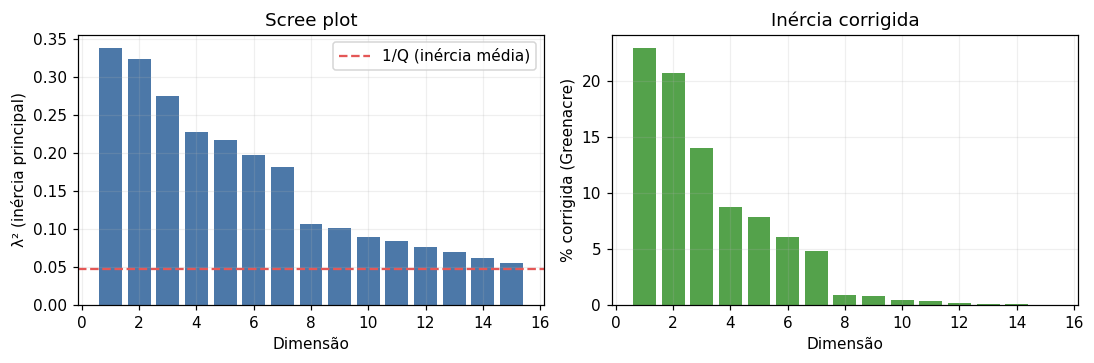

In [ ]:
lam = M["sv"] ** 2
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(range(1, 16), lam[:15], color="#4C78A8")
ax[0].axhline(1 / Q, color="#E45756", ls="--", label="1/Q (inércia média)")
ax[0].set_xlabel("Dimensão"); ax[0].set_ylabel("λ² (inércia principal)")
ax[0].set_title("Scree plot"); ax[0].legend()
ax[1].bar(range(1, 16), tab_in["% Greenacre"].values[:15], color="#54A24B")
ax[1].set_xlabel("Dimensão"); ax[1].set_ylabel("% corrigida (Greenacre)")
ax[1].set_title("Inércia corrigida")
plt.tight_layout(); plt.show()

## 5. Sensibilidade ao tratamento de níveis raros
Comparamos sem agrupamento, 1% (adotado) e 5%: autovalores principais, % corrigida e a correlação (em módulo, pois o sinal do eixo é arbitrário) entre as coordenadas dos indivíduos na Dim 1 e na Dim 2 do caso adotado.

In [ ]:
base = M
linhas = []
for lim in [0, 0.01, 0.05]:
    Xl = agrupar_raros(X, lim) if lim > 0 else X
    m = acm(Xl)
    t = inercia(m)
    linhas.append({
        "limiar": f"{lim:.0%}", "J": m["J"], "Q": m["Q"],
        "λ²₁": m["sv"][0]**2, "λ²₂": m["sv"][1]**2,
        "%Greenacre D1": t["% Greenacre"].iloc[0], "%Greenacre D2": t["% Greenacre"].iloc[1],
        "|corr| F1": abs(np.corrcoef(m["F"][:, 0], base["F"][:, 0])[0, 1]),
        "|corr| F2": abs(np.corrcoef(m["F"][:, 1], base["F"][:, 1])[0, 1]),
    })
display(pd.DataFrame(linhas).round(3).set_index("limiar"))

,J,Q,λ²₁,λ²₂,%Greenacre D1,%Greenacre D2,|corr| F1,|corr| F2
limiar,,,,,,,,
0%,116,21,0.340,0.331,20.580,19.331,0.991,0.969
1%,105,21,0.339,0.325,23.020,20.744,1.000,1.000
5%,87,21,0.338,0.317,30.657,26.286,0.999,0.977


## 6. Níveis: coordenadas, contribuições e cos²

$\text{Ctr}_{jk} = c_j g_{jk}^2/\lambda_k^2$ (quanto o nível constrói o eixo) e $\cos^2_{jk} = g_{jk}^2/\sum_m g_{jm}^2$ (quanto o eixo representa o nível).

In [ ]:
G, F, c, sv = M["G"], M["F"], M["c"], M["sv"]
ctr = c[:, None] * G ** 2 / sv ** 2
cos2 = G ** 2 / (G ** 2).sum(axis=1, keepdims=True)
nj = M["Z"].sum(axis=0).values

niv = pd.DataFrame({
    "variável": [s.split("=")[0] for s in M["niveis"]],
    "n": nj.astype(int),
    "coord 1": G[:, 0], "coord 2": G[:, 1],
    "ctr 1 (%)": ctr[:, 0] * 100, "ctr 2 (%)": ctr[:, 1] * 100,
    "cos² 1": cos2[:, 0], "cos² 2": cos2[:, 1],
}, index=M["niveis"])

# checagem da fórmula de transição: g_jk = (1/λ_k) Σ_i (z_ij/n_j) f_ik
Gcheck = (M["Z"].values.T / nj[:, None]) @ F / sv
print("Fórmula de transição confere:", np.allclose(Gcheck, G))

print("\nTop 10 níveis na Dim 1:")
display(niv.sort_values("ctr 1 (%)", ascending=False).head(10).round(3))
print("Top 10 níveis na Dim 2:")
display(niv.sort_values("ctr 2 (%)", ascending=False).head(10).round(3))

cv = niv.groupby("variável")[["ctr 1 (%)", "ctr 2 (%)"]].sum().round(2)
print("Contribuição por variável (soma dos níveis):")
display(cv.sort_values("ctr 1 (%)", ascending=False).head(10))

Fórmula de transição confere: True

Top 10 níveis na Dim 1:


,variável,n,coord 1,coord 2,ctr 1 (%),ctr 2 (%),cos² 1,cos² 2
ring-type=l,ring-type,1296,-1.718,1.083,6.607,2.744,0.560,0.222
stalk-surface-below-ring=k,stalk-surface-below-ring,2304,-1.276,0.071,6.476,0.021,0.644,0.002
stalk-surface-above-ring=k,stalk-surface-above-ring,2372,-1.234,0.030,6.239,0.004,0.628,0.000
odor=f,odor,2160,-1.211,0.400,5.470,0.623,0.531,0.058
spore-print-color=h,spore-print-color,1632,-1.317,0.971,4.892,2.777,0.436,0.237
ring-type=p,ring-type,3968,0.677,0.303,3.144,0.660,0.438,0.088
bruises=t,bruises,3376,0.676,0.398,2.664,0.965,0.325,0.112
odor=n,odor,3528,0.626,0.083,2.390,0.043,0.301,0.005
stalk-color-below-ring=b,stalk-color-below-ring,432,-1.784,1.170,2.375,1.068,0.179,0.077
stalk-color-above-ring=b,stalk-color-above-ring,432,-1.773,1.158,2.347,1.047,0.177,0.075


Top 10 níveis na Dim 2:


,variável,n,coord 1,coord 2,ctr 1 (%),ctr 2 (%),cos² 1,cos² 2
stalk-root=ausente,stalk-root,2480,-0.307,-1.310,0.403,7.693,0.041,0.755
gill-color=b,gill-color,1728,-0.766,-1.452,1.750,6.576,0.158,0.569
spore-print-color=w,spore-print-color,2388,-0.413,-1.200,0.703,6.211,0.071,0.599
habitat=l,habitat,832,-0.178,-1.748,0.046,4.593,0.004,0.349
ring-type=e,ring-type,2776,-0.173,-0.913,0.143,4.175,0.016,0.432
gill-size=n,gill-size,2512,-0.331,-0.952,0.476,4.110,0.049,0.405
cap-shape=k,cap-shape,828,-0.363,-1.457,0.189,3.175,0.015,0.241
stalk-root=b,stalk-root,3776,-0.285,0.639,0.529,2.789,0.070,0.355
spore-print-color=h,spore-print-color,1632,-1.317,0.971,4.892,2.777,0.436,0.237
ring-type=l,ring-type,1296,-1.718,1.083,6.607,2.744,0.560,0.222


Contribuição por variável (soma dos níveis):


,ctr 1 (%),ctr 2 (%)
variável,,
odor,11.21,6.68
ring-type,9.90,7.70
spore-print-color,9.83,11.18
stalk-surface-below-ring,9.07,0.27
stalk-surface-above-ring,8.86,0.23
stalk-color-above-ring,8.71,5.53
stalk-color-below-ring,8.52,5.28
gill-color,6.91,11.85
population,4.83,5.62


## 7. Variável suplementar: comestível / venenoso

A classe **não entra** no cálculo dos eixos. Suas modalidades são projetadas como baricentros dos indivíduos que as possuem, usando a mesma fórmula de transição:
$g^{sup}_{sk} = \frac{1}{\lambda_k}\sum_i \frac{z_{is}}{n_s} f_{ik}$.

Indicadores: **cos²** (qualidade da projeção), **v-teste** (|v| > 1,96 → posição significativamente diferente da origem no eixo) e a **razão de correlação η²** da classe com cada eixo (0 a 1: quanto a classe é "explicada" pelo eixo).

In [ ]:
Zs = pd.get_dummies(y).astype(float)
ns = Zs.sum(axis=0).values
Gs = (Zs.values.T / ns[:, None]) @ F / sv            # coords principais
d2 = (Gs ** 2).sum(axis=1)
cos2_s = Gs ** 2 / d2[:, None]
vtest = Gs * np.sqrt(ns * (n - 1) / (n - ns))[:, None]
ps = ns / n
eta2 = (ps[:, None] * Gs ** 2).sum(axis=0)            # razão de correlação por eixo

sup = pd.DataFrame({
    "n": ns.astype(int),
    "coord 1": Gs[:, 0], "coord 2": Gs[:, 1], "coord 3": Gs[:, 2],
    "cos² 1": cos2_s[:, 0], "cos² 2": cos2_s[:, 1],
    "v-teste 1": vtest[:, 0], "v-teste 2": vtest[:, 1],
}, index=Zs.columns)
display(sup.round(3))

# checagem independente de η² na Dim 1 (variância entre grupos / variância total)
f1 = F[:, 0]
eta_dir = sum(((y == g).mean()) * f1[(y == g).values].mean() ** 2 for g in Zs.columns) / (f1 ** 2).mean()
print(f"η² (Dim 1): fórmula={eta2[0]:.4f}  direto={eta_dir:.4f}")
print("η² da classe nas 5 primeiras dimensões:", np.round(eta2[:5], 3))
print("Eixo mais associado à classe: Dim", int(np.argmax(eta2)) + 1)

,n,coord 1,coord 2,coord 3,cos² 1,cos² 2,v-teste 1,v-teste 2
comestível,4208,0.717,0.212,-0.040,0.552,0.048,66.959,19.813
venenoso,3916,-0.770,-0.228,0.043,0.552,0.048,-66.959,-19.813


η² (Dim 1): fórmula=0.5519  direto=0.5519
η² da classe nas 5 primeiras dimensões: [0.552 0.048 0.002 0.012 0.02 ]
Eixo mais associado à classe: Dim 1


## 8. Mapa dos níveis e dos indivíduos (plano 1–2, com a classe suplementar)

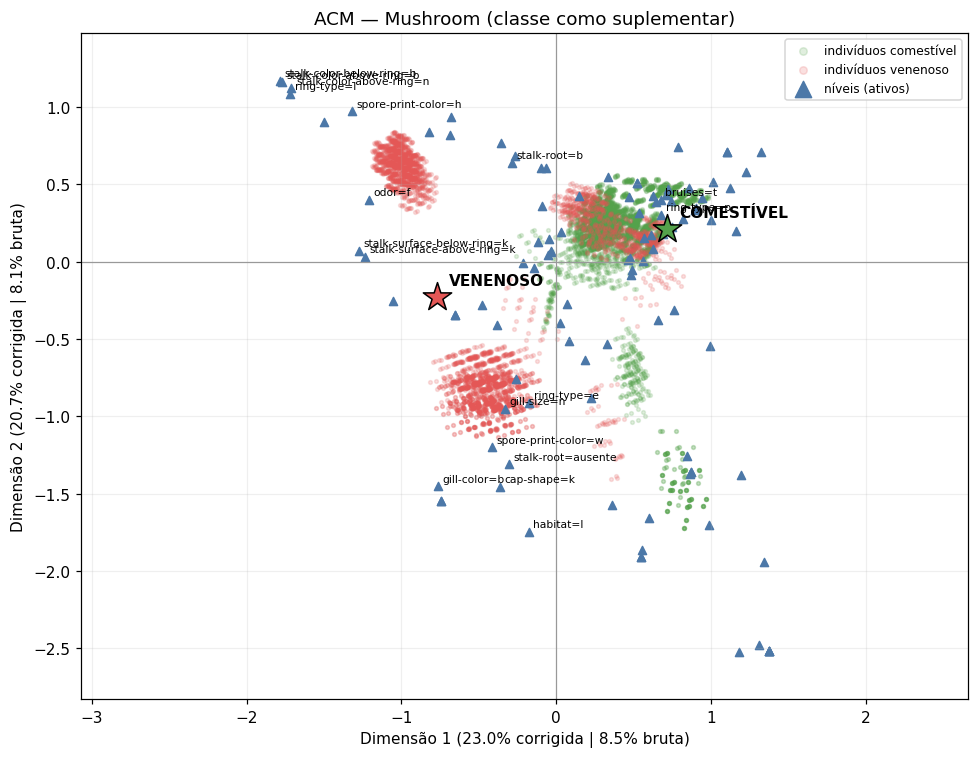

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
cores = {"comestível": "#54A24B", "venenoso": "#E45756"}
for g, col in cores.items():
    msk = (y == g).values
    ax.scatter(F[msk, 0], F[msk, 1], s=6, alpha=0.18, color=col, label=f"indivíduos {g}")

ax.scatter(G[:, 0], G[:, 1], marker="^", s=28, color="#4C78A8", label="níveis (ativos)")
top = (ctr[:, 0] + ctr[:, 1]).argsort()[::-1][:18]
for j in top:
    ax.annotate(M["niveis"][j], (G[j, 0], G[j, 1]), fontsize=7, xytext=(3, 3),
                textcoords="offset points")

for g, col in cores.items():
    i = list(Zs.columns).index(g)
    ax.scatter(Gs[i, 0], Gs[i, 1], marker="*", s=380, color=col, edgecolor="k", zorder=5)
    ax.annotate(g.upper(), (Gs[i, 0], Gs[i, 1]), fontsize=10, fontweight="bold",
                xytext=(8, 8), textcoords="offset points")

tg = tab_in["% Greenacre"]
ax.axhline(0, color="0.6", lw=0.8); ax.axvline(0, color="0.6", lw=0.8)
ax.set_xlabel(f"Dimensão 1 ({tg.iloc[0]:.1f}% corrigida | {tab_in['% bruta'].iloc[0]:.1f}% bruta)")
ax.set_ylabel(f"Dimensão 2 ({tg.iloc[1]:.1f}% corrigida | {tab_in['% bruta'].iloc[1]:.1f}% bruta)")
ax.set_aspect("equal", adjustable="datalim"); ax.margins(0.1)
ax.legend(loc="best", fontsize=8, markerscale=2)
ax.set_title("ACM — Mushroom (classe como suplementar)")
plt.tight_layout(); plt.show()

**Como ler:** níveis próximos entre si (mesma ou outras variáveis) tendem a ocorrer nos mesmos cogumelos; níveis longe da origem são os que mais caracterizam um eixo. Comestível/venenoso são pontos suplementares: se ficam nos extremos opostos de um eixo com η² alto, esse eixo "carrega" a diferença entre as classes. Lembrar que o sinal do eixo é arbitrário.

## 9. Existe um atributo que, sozinho, praticamente separa os dois grupos?

A ACM descreve associações gerais; para responder essa pergunta, medimos a separação **atributo a atributo**, direto contra a classe:

- **Pureza**: acurácia da regra "prever a classe majoritária de cada nível" (em amostra);
- **Pureza em validação cruzada (5 folds)**: mesma regra, mas aprendida em treino e avaliada em teste — evita enganar-se com variáveis de muitos níveis;
- **V de Cramér** com a classe.

In [ ]:
def pureza(x, yv):
    t = pd.crosstab(x, yv)
    return t.max(axis=1).sum() / len(x)

def pureza_cv(x, yv, k=5, seed=0):
    x, yv = x.reset_index(drop=True), yv.reset_index(drop=True)
    acertos = 0
    for tr, te in KFold(k, shuffle=True, random_state=seed).split(x):
        regra = pd.crosstab(x.iloc[tr], yv.iloc[tr]).idxmax(axis=1)
        pred = x.iloc[te].map(regra).fillna(yv.iloc[tr].mode()[0])
        acertos += (pred.values == yv.iloc[te].values).sum()
    return acertos / len(x)

def cramer(x, yv):
    t = pd.crosstab(x, yv)
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

base_rate = y.value_counts(normalize=True).max()
sep = pd.DataFrame({
    "níveis": X.nunique(),
    "pureza": [pureza(X[v], y) for v in X.columns],
    "pureza CV": [pureza_cv(X[v], y) for v in X.columns],
    "V Cramér": [cramer(X[v], y) for v in X.columns],
}).sort_values("pureza CV", ascending=False)
print(f"Referência (sempre a classe majoritária): {base_rate:.3f}")
display(sep.head(10).round(3))

Referência (sempre a classe majoritária): 0.518


,níveis,pureza,pureza CV,V Cramér
odor,9,0.985,0.985,0.971
spore-print-color,9,0.868,0.868,0.753
gill-color,12,0.805,0.805,0.681
ring-type,5,0.775,0.775,0.603
stalk-surface-above-ring,4,0.774,0.774,0.588
stalk-surface-below-ring,4,0.766,0.766,0.575
gill-size,2,0.756,0.756,0.540
bruises,2,0.744,0.744,0.502
population,6,0.722,0.722,0.487
stalk-color-above-ring,9,0.716,0.716,0.525


In [ ]:
melhor = sep.index[0]
print(f"Melhor atributo: {melhor}")
t = pd.crosstab(X[melhor], y, margins=True)
display(t)
display((pd.crosstab(X[melhor], y, normalize="index") * 100).round(1))
erros = pd.crosstab(X[melhor], y)
erros_n = int((erros.sum(axis=1) - erros.max(axis=1)).sum())
print(f"Cogumelos que a regra classificaria errado: {erros_n} de {len(X)}")

Melhor atributo: odor


poisonous,comestível,venenoso,All
odor,,,
odor=a,400,0,400
odor=c,0,192,192
odor=f,0,2160,2160
odor=l,400,0,400
odor=m,0,36,36
odor=n,3408,120,3528
odor=p,0,256,256
odor=s,0,576,576
odor=y,0,576,576


poisonous,comestível,venenoso
odor,,
odor=a,100.0,0.0
odor=c,0.0,100.0
odor=f,0.0,100.0
odor=l,100.0,0.0
odor=m,0.0,100.0
odor=n,96.6,3.4
odor=p,0.0,100.0
odor=s,0.0,100.0
odor=y,0.0,100.0


Cogumelos que a regra classificaria errado: 120 de 8124


**Ponto de atenção sobre "separar":** pureza próxima de 1 não é suficiente se o erro restante for do tipo mais perigoso (classificar um cogumelo **venenoso como comestível**). Abaixo, o erro de cada tipo para a melhor regra.

In [ ]:
regra = pd.crosstab(X[melhor], y).idxmax(axis=1)
pred = X[melhor].map(regra)
print(pd.crosstab(y.rename("real"), pred.rename("previsto")))
fn = ((y == "venenoso") & (pred == "comestível")).sum()
print(f"\nVenenosos classificados como comestíveis: {fn} "
      f"({fn / (y == 'venenoso').sum():.2%} dos venenosos)")

previsto    comestível  venenoso
real                            
comestível        4208         0
venenoso           120      3796

Venenosos classificados como comestíveis: 120 (3.06% dos venenosos)


## 10. Resumo automático das conclusões

In [ ]:
d1 = tab_in.iloc[0]
print(f"- {Q} atributos ativos, {J} níveis, n={n}; classe e nada mais como suplementar.")
print(f"- Dim 1: λ²={d1['inércia (λ²)']:.3f} ({d1['% bruta']:.1f}% bruta, {d1['% Greenacre']:.1f}% corrigida);"
      f" Dim 2: {tab_in.iloc[1]['% bruta']:.1f}% bruta, {tab_in.iloc[1]['% Greenacre']:.1f}% corrigida.")
print(f"- Eixo mais associado à classe: Dim {int(np.argmax(eta2)) + 1} (η²={eta2.max():.3f}).")
print(f"- Atributo mais separador: {melhor} — pureza {sep.loc[melhor, 'pureza']:.3f} "
      f"(CV {sep.loc[melhor, 'pureza CV']:.3f}; referência {base_rate:.3f}), "
      f"{fn} venenosos classificados como comestíveis.")

- 21 atributos ativos, 105 níveis, n=8124; classe e nada mais como suplementar.
- Dim 1: λ²=0.339 (8.5% bruta, 23.0% corrigida); Dim 2: 8.1% bruta, 20.7% corrigida.
- Eixo mais associado à classe: Dim 1 (η²=0.552).
- Atributo mais separador: odor — pureza 0.985 (CV 0.985; referência 0.518), 120 venenosos classificados como comestíveis.


### Como redigir a conclusão
Reporte: (i) as decisões (suplementar, `veil-type` removida, ausentes como nível, limiar de 1% e a sensibilidade); (ii) inércia **bruta e corrigida** das dimensões retidas; (iii) onde a classe cai nos eixos (cos², v-teste, η²); (iv) o atributo mais separador com pureza **em validação cruzada**, e o número de venenosos classificados como comestíveis, que é o erro que importa na prática. Cuidado de interpretação: a ACM mostra **associação**, não regra de decisão; "separar" deve ser dito com base na tabela atributo × classe da seção 9, não apenas na posição no mapa.